In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import json


# Configuring display settings
plt.rcParams['figure.figsize'] = (12, 9)
sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings("ignore", category=FutureWarning)


In [4]:
# Import config variable
with open("../../config.json") as f:
    cfg = json.load(f)
    
target = cfg["rf"]        
file_name = cfg["rf_file_name"]   
random_state = cfg["split"]["random_state"]  
# Load the dataset
data = pd.read_csv(f"../../data/{file_name}.csv")

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

X = data.drop(columns=[target])
y = data[target]

# Tirage de 4 seeds aléatoires différentes
master_rng = np.random.default_rng(seed=99)
seeds = master_rng.choice(10000, size=4, replace=False).tolist()
print("Seeds sélectionnées :", seeds)

# Split fixe utilisé par la grille de recherche ci-dessous
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Fitting 5 folds for each of 1296 candidates, totalling 6480 fits
Meilleurs paramètres: {'colsample_bytree': 0.6, 'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 1500, 'reg_alpha': 1.0, 'reg_lambda': 3.0, 'subsample': 0.7}
Meilleur R² (CV): 0.7879201531410217

MAE (test): 0.5811509490013123
RMSE (test): 0.7514248267828483
R² (test): 0.8364239931106567
R² (train): 0.8827247023582458


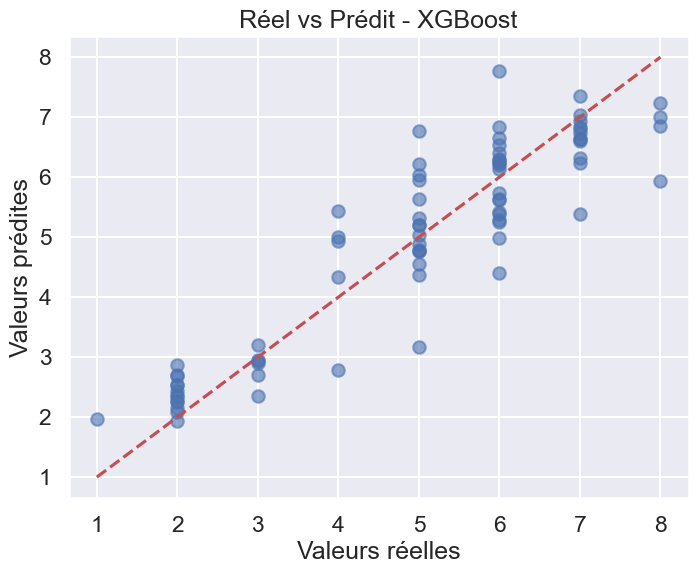

In [6]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

param_grid = {
    'n_estimators': [800, 1000, 1500],
    'learning_rate': [0.005, 0.01],
    'max_depth': [2, 3, 4],
    'min_child_weight': [5, 7, 10],
    'colsample_bytree': [0.5, 0.6],
    'subsample': [0.6, 0.7],
    'reg_alpha': [1.0, 2.0, 3.0], 
    'reg_lambda': [2.0, 3.0],
}


grid_search = GridSearchCV(
    XGBRegressor(),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres:", grid_search.best_params_)
print("Meilleur R² (CV):", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("\nMAE (test):", mean_absolute_error(y_test, y_pred_best))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("R² (test):", r2_score(y_test, y_pred_best))
print("R² (train):", r2_score(y_train, best_model.predict(X_train)))

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - XGBoost')
plt.show()


In [8]:
import joblib
joblib.dump(best_model, 'saved_models/xgboost.pkl')

['saved_models/xgboost.pkl']

In [ ]:
import joblib
import os
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs('saved_models', exist_ok=True)

param_grid = {
    'n_estimators': [800, 1000, 1500],
    'learning_rate': [0.005, 0.01],
    'max_depth': [2, 3, 4],
    'min_child_weight': [5, 7, 10],
    'colsample_bytree': [0.5, 0.6],
    'subsample': [0.6, 0.7],
    'reg_alpha': [1.0, 2.0, 3.0],
    'reg_lambda': [2.0, 3.0],
}

results_per_seed = {}

for seed in seeds:
    print(f"\n{'='*50}")
    print(f"Entraînement XGBoost avec seed = {seed}")
    print(f"{'='*50}")

    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )

    gs = GridSearchCV(
        XGBRegressor(random_state=seed),
        param_grid,
        cv=5,
        scoring='r2',
        n_jobs=-1,
        verbose=0
    )
    gs.fit(X_train_s, y_train_s)
    print(f"Meilleurs params : {gs.best_params_}")

    model_s = gs.best_estimator_

    y_pred_s = model_s.predict(X_test_s)
    r2_test  = r2_score(y_test_s, y_pred_s)
    mae_test = mean_absolute_error(y_test_s, y_pred_s)
    mse_test = mean_squared_error(y_test_s, y_pred_s)
    r2_train = r2_score(y_train_s, model_s.predict(X_train_s))

    print(f"R² train : {r2_train:.4f}")
    print(f"R² test  : {r2_test:.4f}")
    print(f"MAE test : {mae_test:.4f}")
    print(f"RMSE test: {np.sqrt(mse_test):.4f}")

    results_per_seed[seed] = {
        "r2_train":    r2_train,
        "r2_test":     r2_test,
        "mae_test":    mae_test,
        "rmse_test":   np.sqrt(mse_test),
        "best_params": gs.best_params_,
    }

    joblib.dump(model_s, f'saved_models/xgboost_seed_{seed}.pkl')
    print(f"  -> saved_models/xgboost_seed_{seed}.pkl")

print("\n\n=== Récapitulatif ===")
for s, m in results_per_seed.items():
    print(f"seed={s:5d}  R²_train={m['r2_train']:.4f}  R²_test={m['r2_test']:.4f}  MAE={m['mae_test']:.4f}  RMSE={m['rmse_test']:.4f}")